In [7]:
from scr import mutation_estimation

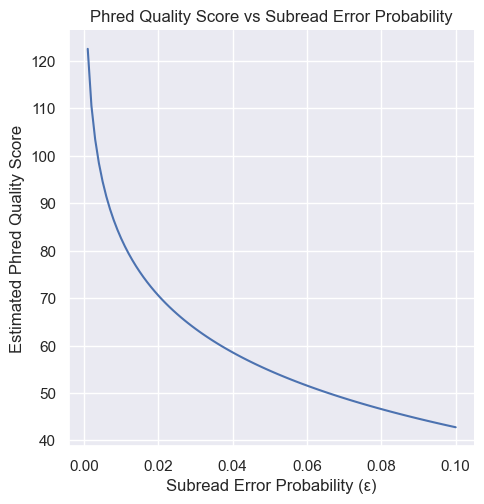

In [8]:
mutation_estimation.plot_phred_eps_dependency(0.001, 0.1, 100, 6)

### Cosmic Mutations

In [1]:
import pandas as pd

In [2]:
mutations = pd.read_csv("data/nanoseq_mutation_data.tsv", sep="\t")
genome_tri_prop_path = "data/h19_tri32.csv"
seq_path = "data/tnfrsf14.fasta"

Length of target sequence: 9744


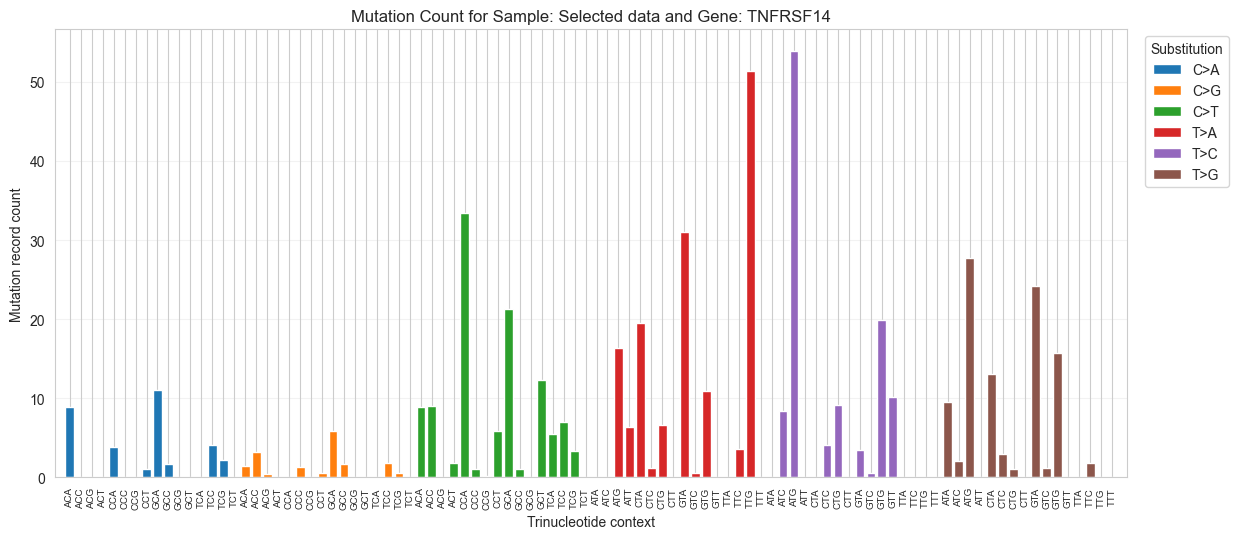

In [3]:
from scr.sbs96_computation import (
    add_sample_metadata,
    build_sbs96_matrix,
    select_mutations,
    tri_correct,
    plot_sbs96_matrix
)

mutations = add_sample_metadata(mutations)

selected = select_mutations(
    mutations,
    # donor_biopsy_id="PD63118b",
    assay="targeted",
    gene="TNFRSF14",
)

matrix = build_sbs96_matrix(selected)
corr_matrix = tri_correct(mut_matrix=matrix, 
                          genome_tri_prop_path=genome_tri_prop_path,
                          seq_path=seq_path)

sbs96_matrix_ax = plot_sbs96_matrix(corr_matrix)

### Test of EM algorithm

In [4]:
from scr.signature_estimation import em_algorithm, em_visualization, signatures_visualization

In [5]:
cosmic_path = "data/COSMIC_v3.5_SBS_GRCh37.txt"

In [6]:
new_signature_prop, q_function_values, expected_counts_per_signature, normalized_mutation_df = em_algorithm(corr_matrix, cosmic_path, signature_prop=None, max_iter=100, tol=1e-5)

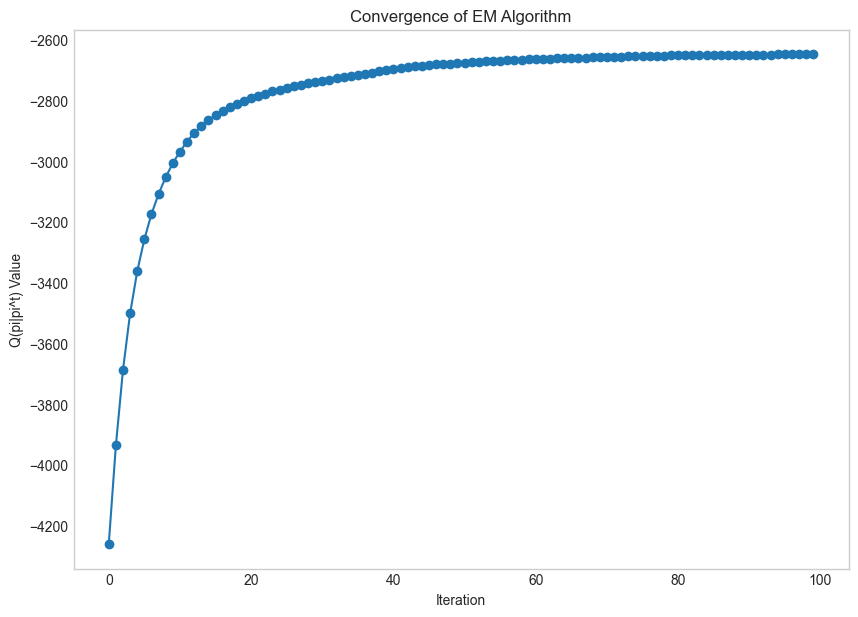

In [7]:
em_visualization(q_function_values)

### Singature composition visualization

In [8]:
totals = expected_counts_per_signature.sum(axis=0)
top_sbs = totals.nlargest(10).index

expected_counts_top_sbs = expected_counts_per_signature.loc[:, top_sbs]

c:\Users\platy\Files\TEMPLE 🏯\Projects\Mutation\Codespace\scr\signature_estimation.py:184: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


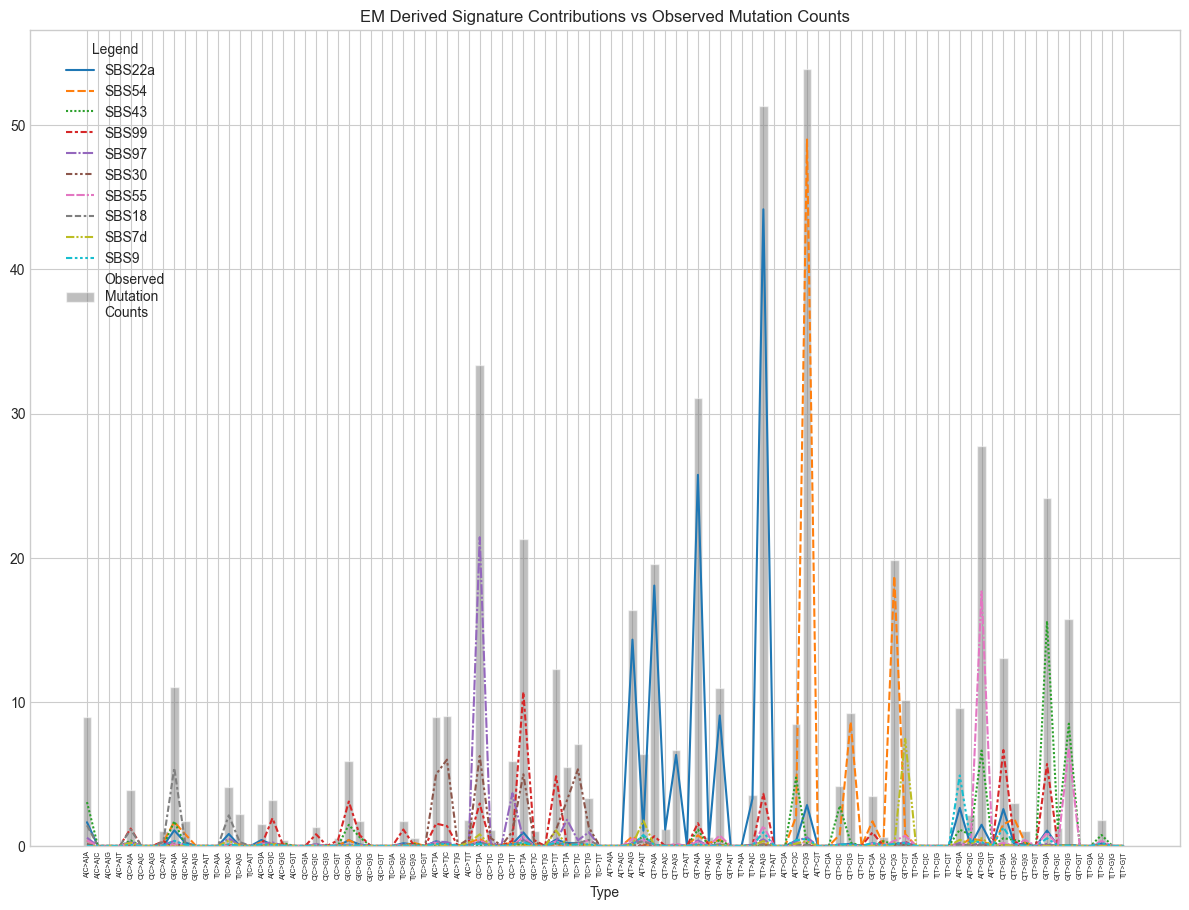

In [9]:
signatures_visualization(expected_counts_per_signature=expected_counts_top_sbs, normalized_matrix=normalized_mutation_df)

### Corrected matrix extraction

In [10]:
corr_matrix["mut_type"] = corr_matrix["tri"].str[0] + "[" + corr_matrix["sub"] + "]" + corr_matrix["tri"].str[2]

In [11]:
corr_matrix

,sub,tri,count,mut_type
0,C>A,ACA,8.964828,A[C>A]A
1,C>A,ACC,0.000000,A[C>A]C
2,C>A,ACG,0.000000,A[C>A]G
3,C>A,ACT,0.000000,A[C>A]T
4,C>A,CCA,3.893984,C[C>A]A
...,...,...,...,...
91,T>G,GTT,0.000000,G[T>G]T
92,T>G,TTA,0.000000,T[T>G]A
93,T>G,TTC,1.778450,T[T>G]C
94,T>G,TTG,0.000000,T[T>G]G


In [12]:
corr_matrix

,sub,tri,count,mut_type
0,C>A,ACA,8.964828,A[C>A]A
1,C>A,ACC,0.000000,A[C>A]C
2,C>A,ACG,0.000000,A[C>A]G
3,C>A,ACT,0.000000,A[C>A]T
4,C>A,CCA,3.893984,C[C>A]A
...,...,...,...,...
91,T>G,GTT,0.000000,G[T>G]T
92,T>G,TTA,0.000000,T[T>G]A
93,T>G,TTC,1.778450,T[T>G]C
94,T>G,TTG,0.000000,T[T>G]G


In [13]:
corr_matrix.set_index(["mut_type"], inplace=True)

In [14]:
corr_matrix = corr_matrix[["count"]]

In [15]:
corr_matrix.rename(columns={"count": "PatientsCombinedTNFRSF14"}, inplace=True)

C:\Users\platy\AppData\Local\Temp\ipykernel_6820\2816304798.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  corr_matrix.rename(columns={"count": "PatientsCombinedTNFRSF14"}, inplace=True)


In [16]:
corr_matrix.to_csv("data/tnfrsf14_sbs96_matrix.csv")